# Finding double bottom patterns with data from Alpaca

Defines and uses functions for:
- get_data - Gets data for a symbol(s) based on a timeframe and start and end dates. Returns a dataframe
- 

In [1]:
from datetime import datetime
from collections import defaultdict
import pandas as pd
import numpy as np
from scipy.signal import argrelextrema
import matplotlib.pyplot as plt 
from alpaca.data.timeframe import TimeFrame
from alpaca.data.historical import StockHistoricalDataClient
from alpaca.data.requests import StockBarsRequest

stock_client = StockHistoricalDataClient('PKMDAQ4V5CCOOPF8BUUR',
                                        'HjCdK5Cgsr7vTMCveXibh4txCY1VjBfQvO6Ggw68')

In [3]:
def get_data(symbol_or_symbols, timeframe, start, end):
    """Get the data for a list of stocks

    Parameters
    ----------
    symbol_or_symbols : str or List[str]
        The symbol or list of symbols to get the data for
    timeframe : TimeFrame
        The timeframe to get the data for
    start : datetime
        The start of the data
    end : datetime
        The end of the data

    Returns
    -------
    DataFrame
        The data for the given stocks.
        Returns a BarSet which is a dictionary keyed by symbol with a List of Bars
        A Bar is a includes the symbol, timestamp, open, high, low, close, volume and
        optionally the trade count, vwap and exchange
    """

    # Set up the parameters
    request_params = StockBarsRequest(
        symbol_or_symbols=symbol_or_symbols,
        timeframe=timeframe, # type: ignore
        start=start,
        end=end
    )

    # Get the stock data
    # Returns a BarSet which is a dictionary keyed by symbol with a List of Bars
    # A Bar is a includes the symbol, timestamp, open, high, low, close, volume and
    # optionally the trade count, vwap and exchange
    
    bars = stock_client.get_stock_bars(request_params)

    # Convert it to a dataframe
    all_data = bars.df # type: ignore
    all_data.drop(columns=['trade_count', 'vwap'], inplace=True)
    all_data.dropna(inplace=True)
    all_data = all_data[~all_data.index.duplicated()]
    # all_data.replace(0, method='bfill', inplace=True)
    print(all_data.head())
    return all_data

In [4]:
def get_max_min(prices, smoothing, window_range):
    """Find the turning points in the closing prices

    Parameters
    ----------
    prices : DataFrame
        Stock prices with columns for timestamp and close
    smoothing : int
        The number of data points to use in the moving average
    window_range : int
        The number of data points to use in the local max/min search

    Returns
    -------
    max_min : Series
        The turning points with columns for sequence number of row in the prices and the close
    """
    # print(f"type prices {type(prices)}")
    # print(f"prices\n{prices.head(20)}")
    # print(f"type smoothing {type(smoothing)}")
    # print(f"value smoothing {smoothing}")
    # print(f"type window_range {type(window_range)}")
    # print(f"value window_range {window_range}")
    # 'Calculate the mean(average) of the closing prices using a window of length smoothing'
    # 'and drop the NaN values, returning a Pandas Series with the timestamp as the index'
    smooth_prices = prices['close'].rolling(window=smoothing).mean().dropna() # Pandas Series
    # print(f"type smooth_prices {type(smooth_prices)}")
    # print(f"smooth_prices\n{smooth_prices.head(20)}")
    # 'Get the indices of the local maxima and local minima in the smoothed prices'
    # 'Returns an array '
    local_max = argrelextrema(smooth_prices.values, np.greater)[0] # numpy ndarray
    local_min = argrelextrema(smooth_prices.values, np.less)[0] # numpy ndarray
    # print(f"type local_max {type(local_max)}")
    # print(f"head local_max {local_max[0:5]}")    # [ 2 11 17 22 27]  2021-01-04 21:00:00+00:00
    # print(f"type local_min {type(local_min)}")
    # print(f"head local_min {local_min[0:5]}")    # [ 8 13 19 23 34]
    price_local_max_dt = [] # List
    # Get the max closing price in the 'window_range' prices either side of the local maxima which is based on the smoothed prices
    for i in local_max:
        if (i>window_range) and (i<len(prices)-window_range):
            price_local_max_dt.append(prices.iloc[i-window_range:i+window_range]['close'].idxmax()) # 131.4489
    # print(f"type price_local_max_dt {type(price_local_max_dt)}")
    # print(f"first five price_local_max_dt {price_local_max_dt[0:5]}")  # first five price_local_max_dt ['2021-01-04 14:00:00', '2021-01-05 10:00:00', '2021-01-05 14:00:00', '2021-01-05 14:00:00', '2021-01-05 22:00:00']
    price_local_min_dt = [] # List
    # Get the min closing price in the 'window_range' prices either side of the local minima which is based on the smoothed prices
    for i in local_min:
        if (i>window_range) and (i<len(prices)-window_range):
            price_local_min_dt.append(prices.iloc[i-window_range:i+window_range]['close'].idxmin())
    # print(price_local_min_dt[0:5])  
    # subset of prices for max dates
    maxima = pd.DataFrame(prices.loc[price_local_max_dt]) # pandas DataFrame
    minima = pd.DataFrame(prices.loc[price_local_min_dt])
    # print(f"head of maxima {maxima.head()}")
    # print(minima.head())
    # subset of prices for max and min dates
    max_min = pd.concat([maxima, minima]).sort_index()
    max_min.index.name = 'date'
    max_min = max_min.reset_index()
    max_min = max_min[~max_min.date.duplicated()]
    # print(f"first five max_min {max_min[0:5]}")
    p = prices.reset_index()   
    # Get the sequence number of row in the prices DF for the max and min dates
    max_min['day_num'] = p[p['timestamp'].isin(max_min.date)].index.values
    max_min = max_min.set_index('day_num')['close']
    # print(f"first five max_min 2 {max_min[0:5]}")
    
    return max_min

In [5]:
def find_patterns(max_min, max_pattern_length=30):
    """Find the patterns in the closing prices. Note that the patterns must
    play out in less than max_pattern_length units.
    Double Bottoms:
        A > B,C,D
        B,D < C
        abs(B-D) < np.mean([B,D]) * 0.05  ensures bottom of W is reasonably level

    Parameters
    ----------
    max_min : Series
        The turning points with columns for sequence number of row in the prices and the close
    max_pattern_length : int, optional
        The pattern must play out in up to this many data points, by default 30

    Returns
    -------
    Dictionary
        The pattern type is the key and the start and end indexes of the patterns 
        make up a list of tuples for the value e.g. {'DB': [(6, 21), (30, 44)]}
    """

    patterns = defaultdict(list)
    
    # Window range is 4 units
    for i in range(4, len(max_min)):  
        # print(f"i {i}")
        window = max_min.iloc[i-4:i]
        # print(f"window {window}")
        
        # Pattern must play out in less than max_pattern_length units
        # print(f"window_index 0 {window.index[0]}")
        # print(f"window_index -1 {window.index[-1]}")
        # Subtract the first index from the last index to check how long the pattern is.
        if window.index[-1] - window.index[0] > max_pattern_length:      
            continue   
            
        a, b, c, d = window.iloc[0:4]
                
        # IHS
        # if a<strong and c<a and c<e and c<d and e<d and abs(b-d)<=np.mean([b,d])*0.02:
        #        patterns['IHS'].append((window.index[0], window.index[-1]))
        
        # double bottom (DB)
        if a>b and a>c and a > d and b<c and d<c and abs(b-d)<=np.mean([b,d])*0.05:
            # Add the pattern type (key) with its start and end index (value as a list of tuples) 
            # to the patterns dictionary. e.g. {'DB': [(6, 21), (30, 44)]}
            patterns['DB'].append((window.index[0], window.index[-1]))
    
    # print(f"type patterns {type(patterns)}")
    # print(f"patterns {patterns}")
    # print(f"patterns.items {patterns.items()}")
    # print(f"[x for x in patterns.items()] {[x for x in patterns.items()]}")
    # print(f"[x for x in patterns.items()][0] {[x for x in patterns.items()][0]}")
    # print(f"[x for x in patterns.items()][0][1] {[x for x in patterns.items()][0][1]}")
    
    return patterns

In [6]:
def plot_minmax_patterns(prices, max_min, patterns, stock, smoothing, window_range):
    """Plot the min max patterns on the stock price chart

    Parameters
    ----------
    prices : DataFrame
        Stock data containing timestamp and OHLCV
    max_min : Series
        The turning points with columns for sequence number of row in the prices and the close
    patterns : Dictionary
        The pattern type is the key and the start and end indexes of the patterns       
        make up a list of tuples for the value e.g. {'DB': [(6, 21), (30, 44)]}
    stock : String
        The stock symbol
    smoothing : int
        The number of data points to use in the moving average
    window_range : int
        The number of data points to use in the local max/min search
    """
    
    incr = str((prices.index[1] - prices.index[0]).seconds/60)
    
    if len(patterns) == 0:
        pass
    else:
        
        num_pat = len([x for x in patterns.items()][0][1])
        f, axes = plt.subplots(1, 2, figsize=(16, 5))
        axes = axes.flatten()
        # print(f"prices {prices}")
        # print(f"prices reset index {prices.reset_index()}")
        prices_ = prices.reset_index()['close']
        # print(f"prices_ {prices_}")
        axes[0].plot(prices_)
        axes[0].scatter(max_min.index, max_min, s=100, alpha=.3, color='orange')
        axes[1].plot(prices_)
        for name, end_day_nums in patterns.items():
            for i, tup in enumerate(end_day_nums):
                sd = tup[0]
                ed = tup[1]
                axes[1].scatter(max_min.loc[sd:ed].index,
                    max_min.loc[sd:ed].values,
                    s=200, alpha=.3)
                plt.yticks([])
        plt.tight_layout()
        plt.title('{}: {}: Smoothing {}, Window Ramge {} ({} patterns)'.format(stock, incr, smoothing, window_range, num_pat))

In [7]:
def get_results(prices, patterns, stock, smoothing, window_range):
    """Get the results of the analysis

    Parameters
    ----------
    prices : DataFrame
        Stock data containing timestamp and OHLCV
    patterns : Dictionary
        The pattern type is the key and the start and end indexes of the patterns       
        make up a list of tuples for the value e.g. {'DB': [(6, 21), (30, 44)]}
    stock : String
        The stock symbol
    smoothing : int
        The number of data points to use in the moving average
    window_range : int
        The number of data points to use in the local max/min search
    """
    incr = str((prices.index[1] - prices.index[0]))
    
    #fw_list = [1, 12, 24, 36] 
    fw_list = [1, 2, 3]
    results = []
    if len(patterns.items()) > 0:
        end_dates = [v for k, v in patterns.items()][0]      
        for date in end_dates:  
            param_res = {'stock': stock,
                        'increment': incr,
                        'ema': smoothing,
                        'window': window_range, 
                        'date': date}
            for x in fw_list:
                returns = (prices['close'].pct_change(x).shift(-x).reset_index(drop=True).dropna())
                try:
                    param_res['fw_ret_{}'.format(x)] = returns.loc[date[1]]   
                except Exception as e:
                    param_res['fw_ret_{}'.format(x)] = e
            results.append(param_res)  
    else:
        param_res = {'stock': stock,
                    'increment': incr,
                    'ema': smoothing,
                    'window': window_range,
                    'date': None}
        for x in fw_list:
            param_res['fw_ret_{}'.format(x)] = None   
        results.append(param_res)
    return pd.DataFrame(results)

In [8]:
def screener(stock_data, smoothing_list, window_range_list, plot, max_pattern_length, results):
    """Process the stock data by stock screening for patterns and plotting the results

    Parameters
    ----------
    stock_data : DataFrame
        Stock data indexed by stock symbol and timestamp with columns for OHLCV
    smoothing_list : int
        A list of the number of data points to use in the moving average
    window_range_list : int
        A list of the number of data points to use in the local max/min search
    plot : bool
        Whether to plot the patterns
    results : bool
        Whether to return the results

    Returns
    -------
    DataFrame
        The results of the screening
    """
    # print(stock_data.head())
    all_results = pd.DataFrame()
    
    "Process the stock data by stock"
    for stock, stock_prices in stock_data.groupby(level=0):
        # "stock - the stock name"
        # "stock_prices - the stock name and prices"
        # print(stock)
        # print(stock_prices)
        # "prices - the timestamp and prices for the stock (no stock name)"
        prices = stock_prices.loc[stock]
        # print(prices.head())
        
        for smoothing in smoothing_list:
            for window_range in window_range_list: 
                max_min = get_max_min(prices, smoothing=smoothing, window_range=window_range)
                patterns = find_patterns(max_min, max_pattern_length)
                
                if plot:
                    plot_minmax_patterns(prices, max_min, patterns, stock, window_range, smoothing)
                    
                if results:
                    all_results = pd.concat([all_results,
                                            get_results(prices, patterns, stock, smoothing, window_range)],
                                            axis=0)
                
    if results:
        return all_results.reset_index(drop=True)

                                    open    high     low   close    volume
symbol timestamp                                                          
AAPL   2021-01-01 00:00:00+00:00  132.69  132.80  132.65  132.71   87628.0
       2021-01-04 09:00:00+00:00  133.31  134.01  133.02  133.60  112129.0
       2021-01-04 10:00:00+00:00  133.60  134.43  133.43  134.30  163257.0
       2021-01-04 11:00:00+00:00  134.22  134.35  133.60  133.99   45136.0
       2021-01-04 12:00:00+00:00  133.92  134.00  133.54  133.95  494894.0


/tmp/ipykernel_1875050/3697308115.py:44: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  all_results = pd.concat([all_results,
/tmp/ipykernel_1875050/3697308115.py:44: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  all_results = pd.concat([all_results,
/tmp/ipykernel_1875050/3697308115.py:44: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. T

  stock        increment  ema  window      date  fw_ret_1  fw_ret_2  fw_ret_3
0  AAPL  3 days 09:00:00    3       5   (6, 21)  0.022667  0.016511  0.014720
1  AAPL  3 days 09:00:00    3       5  (30, 44)  0.003950  0.005372  0.006083
2  AAPL  3 days 09:00:00    3      10   (2, 27)  0.000000 -0.000153 -0.000382
3  AAPL  3 days 09:00:00    5       5   (6, 21)  0.022667  0.016511  0.014720
4  AAPL  3 days 09:00:00    5       5  (22, 44)  0.003950  0.005372  0.006083
5  AAPL  3 days 09:00:00    5      10   (6, 28) -0.000153 -0.000382 -0.001527
6  GOOG  0 days 01:00:00    3       5      None       NaN       NaN       NaN
7  GOOG  0 days 01:00:00    3      10   (4, 24)  0.004042  0.016355  0.012284
8  GOOG  0 days 01:00:00    5       5      None       NaN       NaN       NaN
9  GOOG  0 days 01:00:00    5      10      None       NaN       NaN       NaN


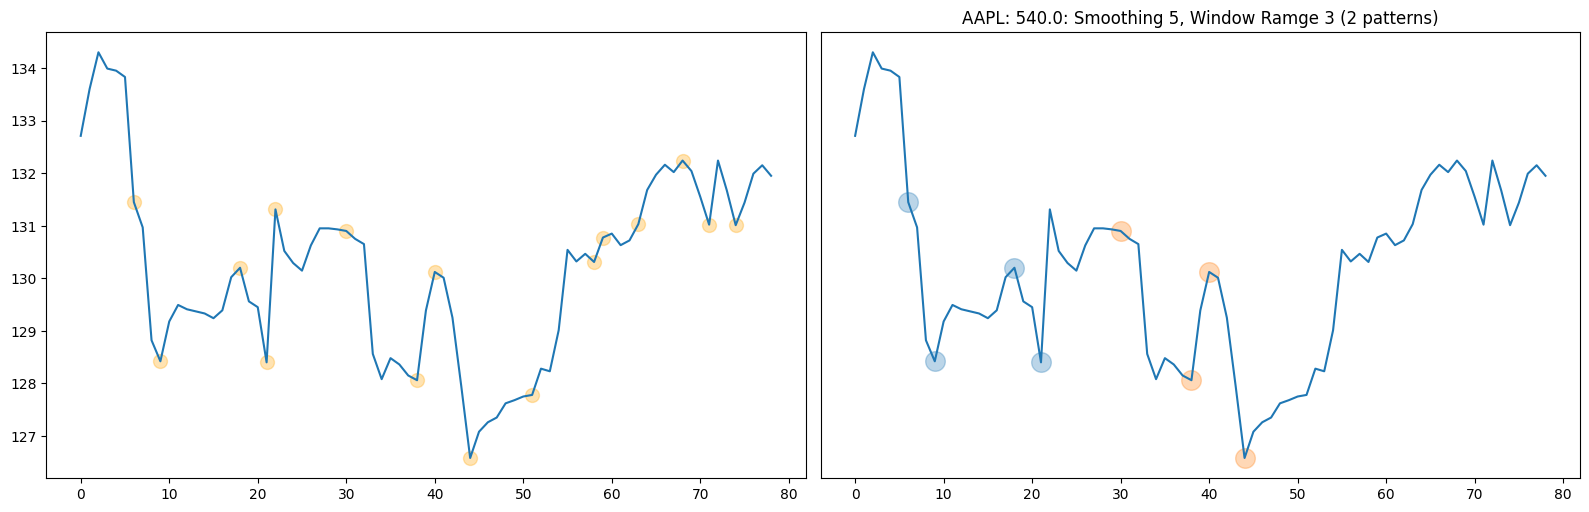

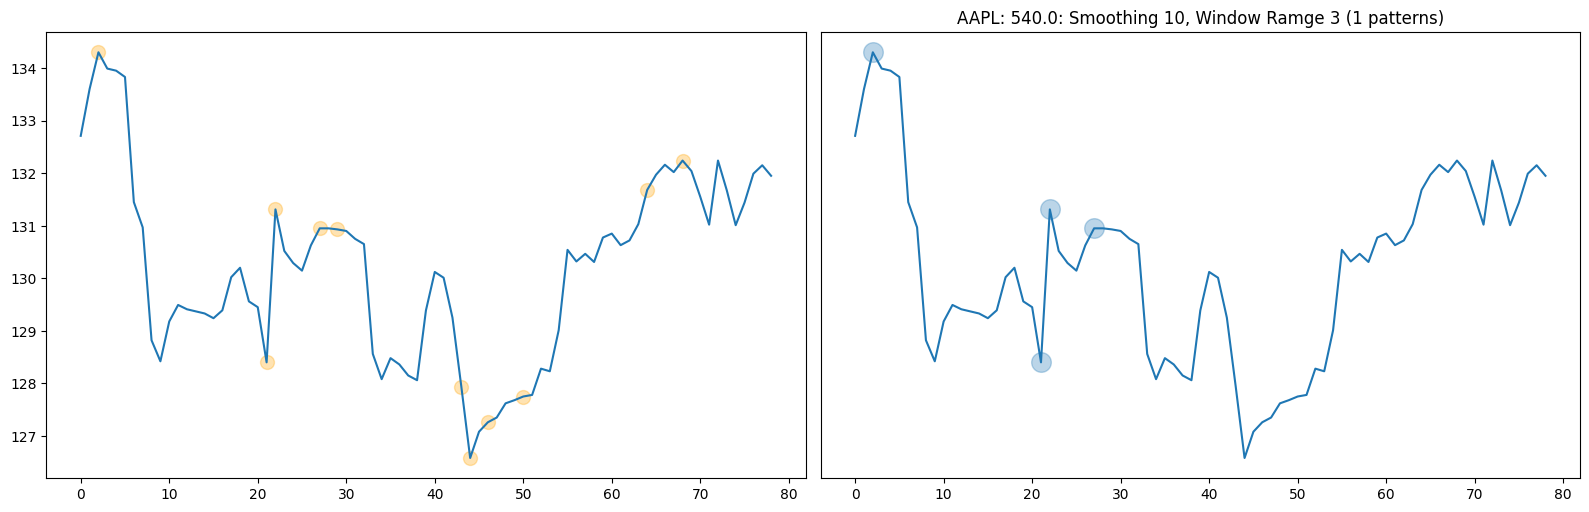

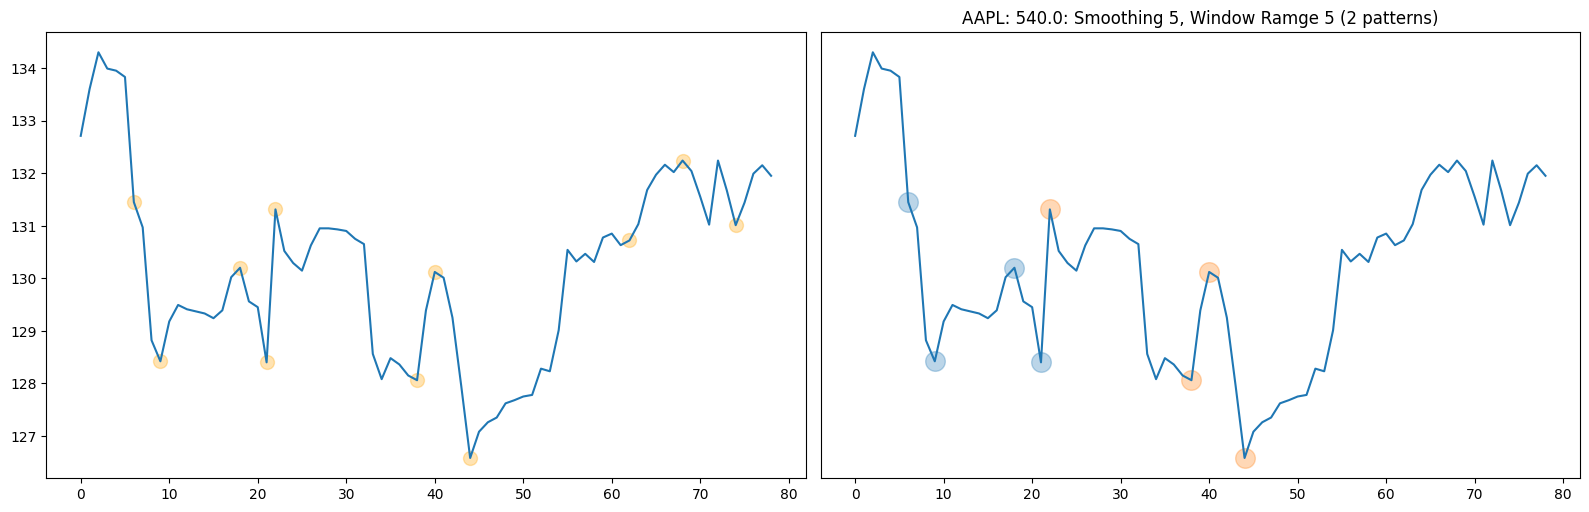

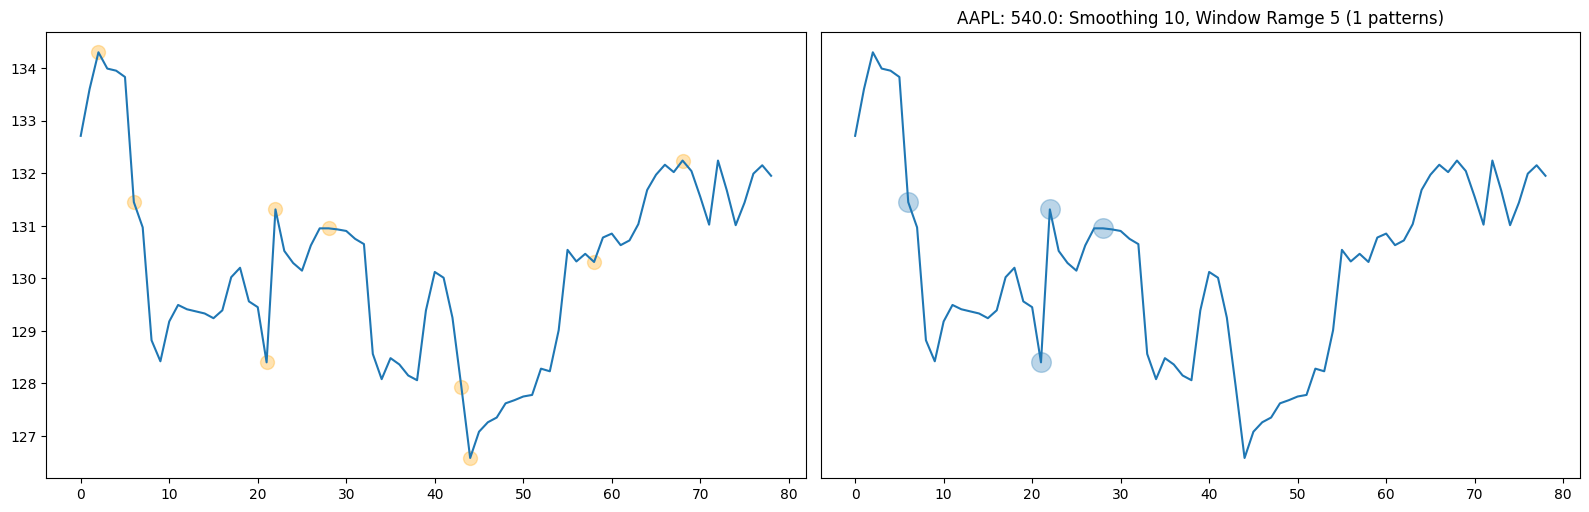

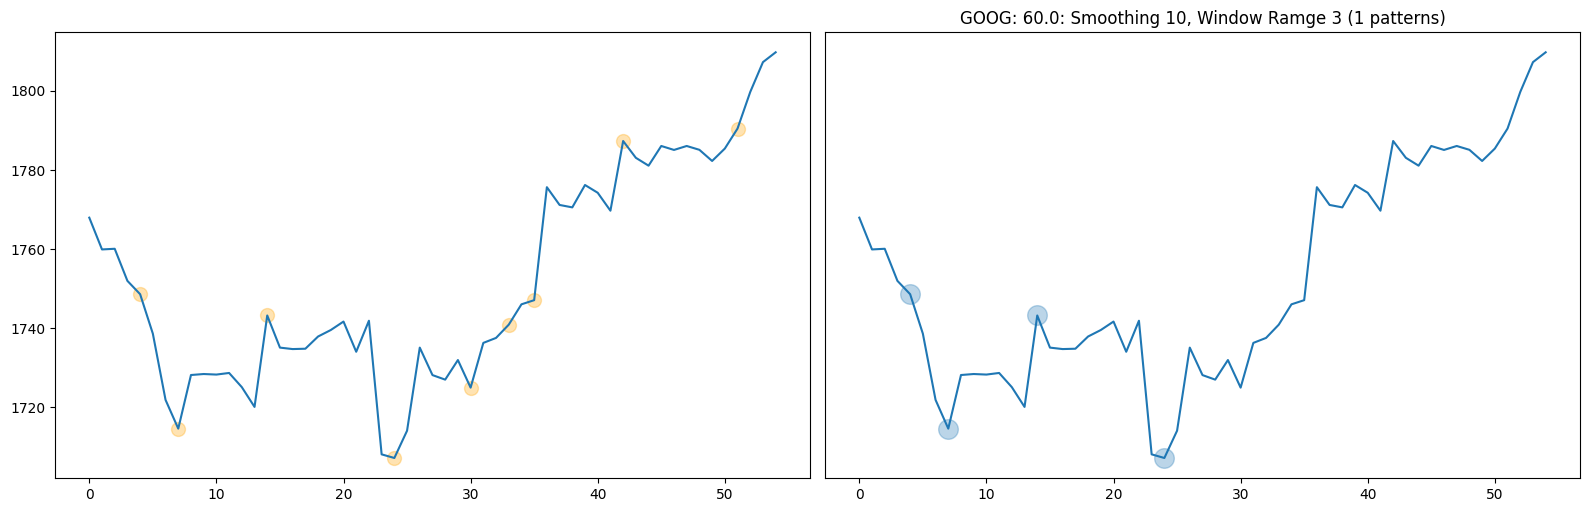

In [9]:
stock_list = ['AAPL',
            'GOOG',
            # 'MFST',
            # 'AMZN',
            # 'TSLA',
            # 'FB',
            # 'NVDA',
            # 'PYPL',
            # 'INTC',
            # 'NFLX',
            ]

stock_data = get_data(stock_list, 
            TimeFrame.Hour, 
            datetime(2021, 1, 1), 
            datetime(2021, 1, 10))

# print(stock_data.head())

# smoothing_list = [3, 5, 10, 20, 30, ]
# window_range_list = [3, 5, 10, 20, 30, ]
smoothing_list = [3,5]
window_range_list = [5,10]
max_pattern_length = 30

results = screener(stock_data, smoothing_list, window_range_list, plot=True, max_pattern_length=max_pattern_length, results=True)
print(results)
